# 19. Replikasi protokol Appiahene et al. (2023) pada dataset Palm
**Penelitian:** Deteksi anemia dari citra pucat (telapak tangan, kuku, konjungtiva) dengan data pooling multi-situs.

**Tujuan:** membandingkan (A) augmentasi sebelum pembagian data seperti pada Appiahene et al. (2023), (B) pembagian data lebih dulu lalu augmentasi hanya pada data latih, dan (C) tanpa augmentasi. Hiperparameter Naive Bayes, k-NN, SVM, dan Decision Tree mengikuti artikel tersebut; LightGBM ditambahkan penulis. Translasi pada artikel tidak diimplementasikan (lima versi per citra) dan CNN tidak disertakan.

**Masukan:** Dataset (Mendeley Data): Palm doi:10.17632/ccr8cm22vz.1, Nail doi:10.17632/2xx4j3kjg2.1, Conjunctiva doi:10.17632/nt7r8hv2pz.1. Letakkan dalam folder `Dataset_Multisite/{Palm,Nail,Conjunctiva}`.

**Keluaran (folder `hasil_revisi`):** `replikasi_protokol_paper.csv`.

**Kaitan dengan naskah:** Bagian 3.1 dan Bagian 3.9, Tabel 13.

**Cara menjalankan:** Colab, Runtime > Run all. CPU sudah cukup; GPU tidak diperlukan. Seed acak = 42 dan urutan file diurutkan (`sorted`) sehingga hasil dapat direproduksi pada versi pustaka yang dicetak di sel kedua.

In [1]:
!pip install lightgbm -q

In [2]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

Mounted at /content/drive


In [3]:
# ===== FUNGSI BERSAMA (identik di keempat notebook) =====
import os, re, hashlib, warnings
import numpy as np, pandas as pd, cv2
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, f1_score, roc_auc_score
from lightgbm import LGBMClassifier
warnings.filterwarnings('ignore')

# ---------- KONFIGURASI (ubah hanya bagian ini) ----------
SEED = 42
BASE = '/content/drive/MyDrive/Dataset_Multisite'   # folder berisi subfolder Palm/, Nail/, Conjunctiva/
OUT  = '/content/drive/MyDrive/hasil_revisi'          # folder keluaran (CSV)
SITES = {'Palm': 0, 'Nail': 1, 'Conjunctiva': 2}
# Filter piksel memeriksa kanal L, R, dan G. Kanal B ikut difilter jika True
# (Appiahene et al. 2023 menuliskan kondisi min < R=G=B < max).
FILTER_INCLUDE_B = False
# True: buang juga citra bernama varian dari citra lain (akhiran FV/RA atau spasi+angka) yang citra dasarnya ada.
BUANG_VARIAN = True
os.makedirs(OUT, exist_ok=True)

# ---------- DAFTAR FILE ----------
def parse_label(name):
    """Label dari awalan nama file (Anemic / Non-Anemic); nama yang mengandung tanda kurung (salinan bernomor) dan awalan tidak dikenali dilewati."""
    if '(' in name: return None
    c = name.lower().replace(' ', '')
    if c.startswith('non-anemic'): return 0
    if c.startswith('anemic'): return 1
    return None

def list_used_files():
    rows = []
    for site, sid in SITES.items():
        d = os.path.join(BASE, site)
        for n in sorted(os.listdir(d)):          # sorted -> urutan deterministik
            lab = parse_label(n)
            if lab is not None:
                rows.append(dict(site=site, site_id=sid, file=n, path=os.path.join(d, n), label=lab))
    return pd.DataFrame(rows)

def md5(path):
    with open(path, 'rb') as f: return hashlib.md5(f.read()).hexdigest()

# ---------- EKSTRAKSI FITUR ----------
def feat_original(img, lo=50, hi=200):
    """Fitur [mean a*, mean b*, mean G] dengan filter piksel. Return (fitur, mask_kosong)."""
    rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
    L, a, b = cv2.split(lab); R, G, B = cv2.split(rgb)
    m = (L > lo) & (L < hi) & (R > lo) & (R < hi) & (G > lo) & (G < hi)
    if FILTER_INCLUDE_B: m &= (B > lo) & (B < hi)
    if m.any(): return [a[m].mean(), b[m].mean(), G[m].mean()], False
    return [0.0, 0.0, 0.0], True

def feat_otsu(img):
    """Fitur dari piksel foreground Otsu (grayscale). Tanpa filter L/R/G. Return (fitur, mask_kosong)."""
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    _, mk = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    m = mk > 0
    if not m.any(): return [0.0, 0.0, 0.0], True
    rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
    _, a, b = cv2.split(lab); G = rgb[:, :, 1]
    return [a[m].mean(), b[m].mean(), G[m].mean()], False

# ---------- PEMBAGIAN DATA & EVALUASI ----------
def split_idx(y, scheme, seed=SEED):
    """Return (train, val, test) berupa indeks. Skema: '80:20', '80:10:10', '70:10:20'."""
    idx = np.arange(len(y))
    if scheme == '80:20':
        tr, te = train_test_split(idx, test_size=0.20, stratify=y, random_state=seed)
        return tr, None, te
    if scheme == '80:10:10':
        tr, tmp = train_test_split(idx, test_size=0.20, stratify=y, random_state=seed)
        va, te = train_test_split(tmp, test_size=0.50, stratify=y[tmp], random_state=seed)
        return tr, va, te
    if scheme == '70:10:20':
        trva, te = train_test_split(idx, test_size=0.20, stratify=y, random_state=seed)
        tr, va = train_test_split(trva, test_size=0.125, stratify=y[trva], random_state=seed)
        return tr, va, te
    raise ValueError(scheme)

def metrics_from(yte, pred, proba):
    tn, fp, fn, tp = confusion_matrix(yte, pred, labels=[0, 1]).ravel()
    assert tn + fp + fn + tp == len(yte), 'TP+TN+FP+FN harus sama dengan jumlah data uji'
    two = len(set(yte)) == 2
    return dict(n_test=len(yte), n_test_anemic=int((yte == 1).sum()), TP=int(tp), TN=int(tn), FP=int(fp), FN=int(fn),
                acc=100*(tp+tn)/len(yte),
                sens=100*tp/(tp+fn) if tp+fn else np.nan,
                spec=100*tn/(tn+fp) if tn+fp else np.nan,
                f1=100*f1_score(yte, pred, zero_division=0),
                auc=100*roc_auc_score(yte, proba) if two else np.nan,
                baseline_mayoritas=100*max((yte == 1).mean(), (yte == 0).mean()))

def fit_lgbm(Xtr, ytr):
    sc = StandardScaler().fit(Xtr)
    m = LGBMClassifier(n_estimators=100, random_state=SEED, verbose=-1).fit(sc.transform(Xtr), ytr)
    return sc, m

def predict_lgbm(sc, m, X):
    proba = m.predict_proba(sc.transform(X))[:, 1]
    return (proba >= 0.5).astype(int), proba

def tandai_dibuang(df):
    """Array boolean (urut baris): True bila baris dibuang pada pembersihan = salinan identik MD5 (satu dipertahankan),
    kedua file pada pasangan identik berlabel berbeda, dan (bila BUANG_VARIAN) citra varian FV/RA. df: indeks 0..n-1 dan kolom md5."""
    konflik = df.groupby('md5').label.transform('nunique') > 1
    dibuang = np.array(df.duplicated('md5', keep='first') | konflik, dtype=bool)   # salinan yang dapat diubah
    if BUANG_VARIAN:
        posisi = np.flatnonzero(~dibuang)
        for a, b in pasangan_varian(df.iloc[posisi].reset_index(drop=True)): dibuang[posisi[a]] = True
    return dibuang

def bersihkan(df):
    """Data bersih untuk semua eksperimen (satu definisi tunggal)."""
    df = df.reset_index(drop=True).copy(); df['md5'] = df['path'].map(md5)
    return df[~tandai_dibuang(df)].reset_index(drop=True)

def cek_kebocoran(md5s, tr, va, te, wajib=True):
    """Pemeriksaan kebocoran: indeks latih/validasi/uji harus saling lepas dan tidak ada citra identik (MD5) lintas partisi.
    Return jumlah citra identik lintas partisi, mis. {'latih-uji': 0}. wajib=True -> hentikan program bila ada pelanggaran."""
    parts = {'latih': set(tr), 'uji': set(te)}
    if va is not None: parts['val'] = set(va)
    nm = sorted(parts)
    for i, a in enumerate(nm):
        for b in nm[i + 1:]:
            assert not (parts[a] & parts[b]), f'Indeks tumpang tindih: {a}-{b}'
    m = {k: set(np.asarray(md5s)[sorted(v)]) for k, v in parts.items()}
    bocor = {f'{a}-{b}': len(m[a] & m[b]) for i, a in enumerate(nm) for b in nm[i + 1:]}
    if wajib: assert all(v == 0 for v in bocor.values()), f'Citra identik lintas partisi: {bocor}'
    return bocor

def pasangan_varian(df):
    """Pasangan (indeks varian, indeks citra dasar) pada df (indeks posisi 0..n-1): nama berakhiran FV/RA atau spasi+angka
    yang nama dasarnya ada pada situs yang sama (mis. Anemic-001FV dengan Anemic-001)."""
    stem = df.file.str.replace(r'\.[A-Za-z]+$', '', regex=True)
    base = stem.str.replace(r'\s\d+$', '', regex=True).str.replace(r'(FV|RA)$', '', regex=True)
    key = {(s, t): i for i, (s, t) in enumerate(zip(df.site, stem))}
    return [(i, key[(s, b)]) for i, (s, t, b) in enumerate(zip(df.site, stem, base)) if b != t and (s, b) in key]

def cek_varian(pasangan, tr, va, te):
    """Jumlah pasangan varian-dasar yang terpisah di partisi berbeda (informasi; idealnya 0)."""
    part = {}
    for ids, nm in [(tr, 'latih'), (va, 'val'), (te, 'uji')]:
        if ids is not None:
            for i in ids: part[i] = nm
    return sum(1 for a, b in pasangan if a in part and b in part and part[a] != part[b])

In [4]:
import sys, numpy, pandas, cv2, sklearn, lightgbm
print('Python', sys.version.split()[0], '| numpy', numpy.__version__, '| pandas', pandas.__version__,
      '| OpenCV', cv2.__version__, '| scikit-learn', sklearn.__version__, '| LightGBM', lightgbm.__version__, '| SEED', SEED)

Python 3.13.16 | numpy 2.4.6 | pandas 2.2.3 | OpenCV 4.14.0 | scikit-learn 1.6.1 | LightGBM 4.6.0 | SEED 42


In [5]:
# ===== REPLIKASI PROTOKOL [1] pada Palm: augmentasi SEBELUM split vs split dulu =====
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

AUG = {'asli': lambda im: im,
       'rot90': lambda im: cv2.rotate(im, cv2.ROTATE_90_CLOCKWISE),
       'rot270': lambda im: cv2.rotate(im, cv2.ROTATE_90_COUNTERCLOCKWISE),
       'flip_horizontal': lambda im: cv2.flip(im, 1),
       'flip_vertikal': lambda im: cv2.flip(im, 0)}   # 5 versi per citra (translasi pada [1] tidak diimplementasikan)

def make_models():   # hiperparameter mengikuti [1] untuk NB, k-NN, SVM, Decision Tree; LightGBM tambahan penulis
    return {'Naive Bayes': GaussianNB(),
            'k-NN (k=100, Euclidean)': KNeighborsClassifier(n_neighbors=100, metric='euclidean', weights='uniform'),
            'SVM (sigmoid, C=100, iter=100, tol=0,1)': SVC(kernel='sigmoid', C=100, max_iter=100, tol=0.1),
            'Decision Tree (leaf>=10, split>=5)': DecisionTreeClassifier(min_samples_leaf=10, min_samples_split=5, random_state=SEED),
            'LightGBM (100)': LGBMClassifier(n_estimators=100, random_state=SEED, verbose=-1)}

palm = bersihkan(list_used_files()); palm = palm[palm.site == 'Palm'].reset_index(drop=True)   # data Palm bersih
y0 = palm.label.to_numpy()
imgs = [cv2.imread(p) for p in palm.path]
# fitur untuk tiap versi augmentasi
F = {k: np.array([feat_original(fn(im))[0] for im in imgs]) for k, fn in AUG.items()}
selisih = max(np.abs(F[k] - F['asli']).max() for k in AUG)
print(f'Selisih maksimum fitur antara citra asli dan hasil rotasi/flip: {selisih:.6f}  (0 = fitur identik)')

def acc_all(Xtr, ytr, Xte, yte):
    sc = StandardScaler().fit(Xtr); res = {}
    for nm, mdl in make_models().items():
        mdl.fit(sc.transform(Xtr), ytr); res[nm] = 100 * (mdl.predict(sc.transform(Xte)) == yte).mean()
    return res

rows = {}
# Protokol A ([1]): semua versi ditumpuk, lalu split acak 70:10:20 -> salinan satu citra bisa di latih dan uji
XA = np.vstack([F[k] for k in AUG]); yA = np.concatenate([y0] * len(AUG)); grupA = np.concatenate([np.arange(len(y0))] * len(AUG))
tr, va, te = split_idx(yA, '70:10:20')
bocor = len(set(grupA[te]) & set(grupA[tr])) / len(set(grupA[te]))
print(f'Protokol A: {100*bocor:.1f}% citra asal data uji juga muncul (sebagai salinan) di data latih')
rows['A. Augmentasi lalu split (seperti [1])'] = acc_all(XA[tr], yA[tr], XA[te], yA[te])
# Protokol B (penelitian ini): split citra asli, augmentasi hanya data latih, uji pada citra asli
tr0, va0, te0 = split_idx(y0, '70:10:20')
print('Pemeriksaan kebocoran protokol B/C:', cek_kebocoran(palm.md5.to_numpy(), tr0, va0, te0))
XB = np.vstack([F[k][tr0] for k in AUG]); yB = np.concatenate([y0[tr0]] * len(AUG))
rows['B. Split lalu augmentasi data latih'] = acc_all(XB, yB, F['asli'][te0], y0[te0])
# Protokol C: tanpa augmentasi
rows['C. Tanpa augmentasi'] = acc_all(F['asli'][tr0], y0[tr0], F['asli'][te0], y0[te0])

tabel = pd.DataFrame(rows).T.round(2)
tabel.to_csv(os.path.join(OUT, 'replikasi_protokol_paper.csv'))
print('\nAkurasi data uji (%):'); print(tabel.to_string())
print('\nAcuan [1]: Naive Bayes 99,96 | k-NN 99,92 | Decision Tree 99,29 | SVM 96,34')

Selisih maksimum fitur antara citra asli dan hasil rotasi/flip: 0.000000  (0 = fitur identik)
Protokol A: 99.7% citra asal data uji juga muncul (sebagai salinan) di data latih
Pemeriksaan kebocoran protokol B/C: {'latih-uji': 0, 'latih-val': 0, 'uji-val': 0}

Akurasi data uji (%):
                                        Naive Bayes  k-NN (k=100, Euclidean)  SVM (sigmoid, C=100, iter=100, tol=0,1)  Decision Tree (leaf>=10, split>=5)  LightGBM (100)
A. Augmentasi lalu split (seperti [1])        56.45                    64.16                                    50.48                               85.74          100.00
B. Split lalu augmentasi data latih           54.81                    58.65                                    50.00                               57.69           69.23
C. Tanpa augmentasi                           54.81                    62.50                                    52.88                               62.50           67.31

Acuan [1]: Naive Bayes 99,96 | k-NN 9

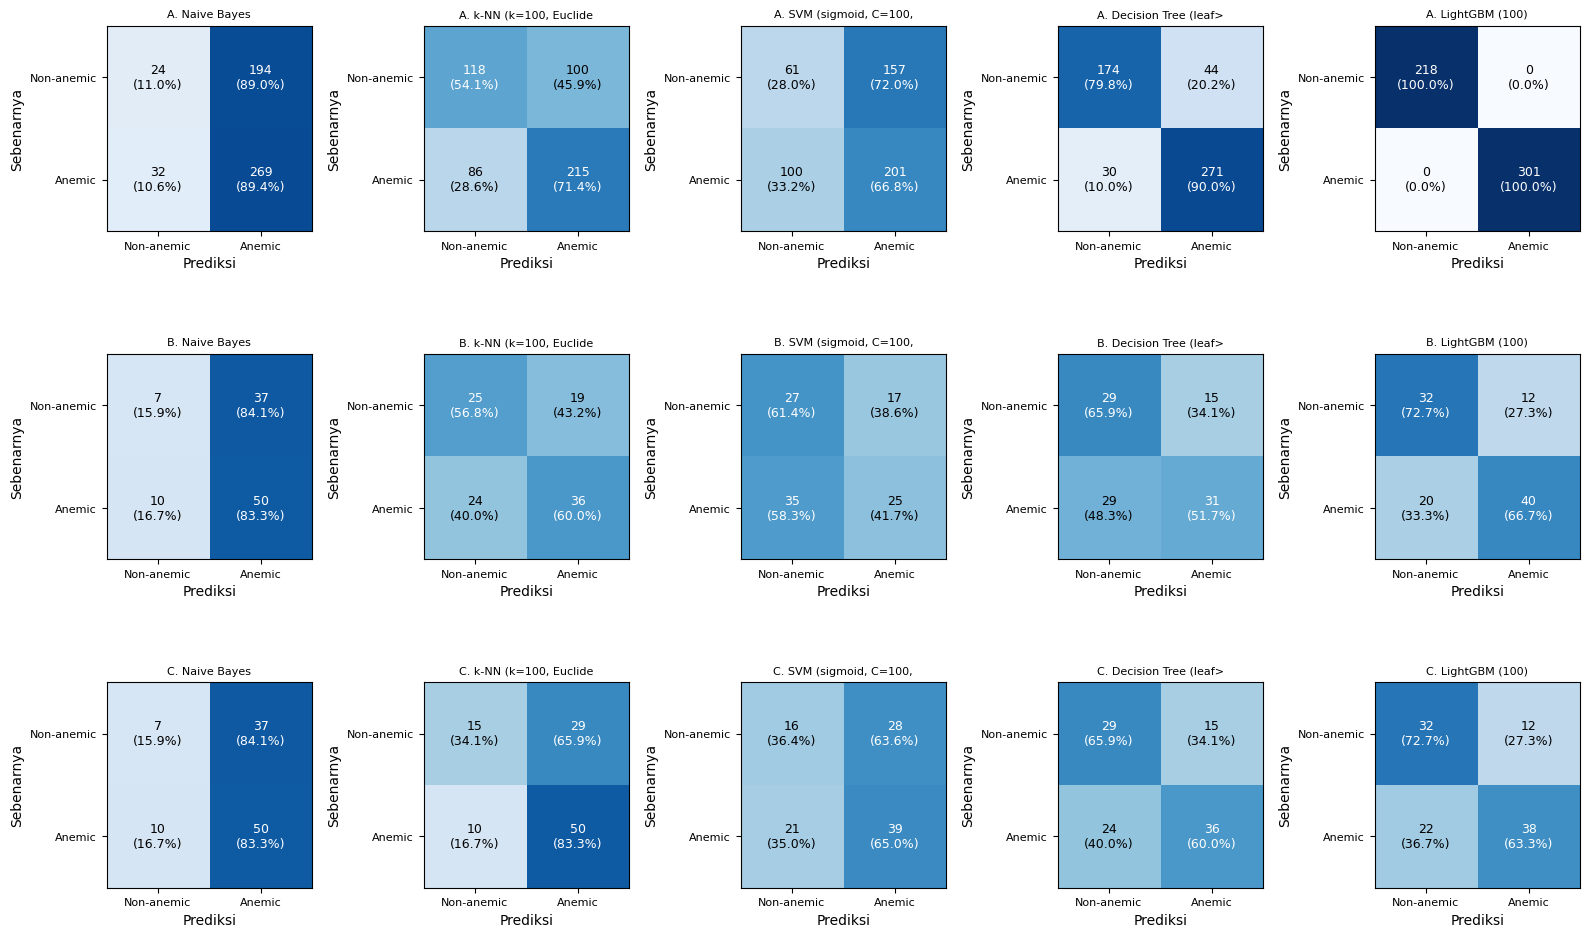

In [8]:
from sklearn.metrics import confusion_matrix
def cm_all(Xtr, ytr, Xte, yte):
    sc = StandardScaler().fit(Xtr); out = {}
    for nm, mdl in make_models().items():
        mdl.fit(sc.transform(Xtr), ytr)
        out[nm] = confusion_matrix(yte, mdl.predict(sc.transform(Xte)), labels=[0, 1])    # [[TN, FP], [FN, TP]]
    return out
CM19 = {'A. Augmentasi lalu split': cm_all(XA[tr], yA[tr], XA[te], yA[te]),
        'B. Split lalu augmentasi data latih': cm_all(XB, yB, F['asli'][te0], y0[te0]),
        'C. Tanpa augmentasi': cm_all(F['asli'][tr0], y0[tr0], F['asli'][te0], y0[te0])}
fig, axs = plt.subplots(3, 5, figsize=(16, 10))
for i, (prot, dd) in enumerate(CM19.items()):
    for j, (nm, cm) in enumerate(dd.items()):
        gambar_cm(cm, f'{prot[:2]} {nm[:20]}', axs[i][j])
plt.tight_layout(); plt.savefig(os.path.join(OUT, 'cm_nb19.png'), dpi=150); plt.show()

In [7]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
OUT = '/content/drive/MyDrive/hasil_revisi'          # folder berisi CSV hasil
LABEL = ['Non-anemic', 'Anemic']

def cm_dari_baris(r):
    """Matriks [[TN, FP], [FN, TP]]: baris = kelas sebenarnya, kolom = prediksi."""
    cm = np.array([[r['TN'], r['FP']], [r['FN'], r['TP']]], dtype=int)
    n = r['n_test'] if 'n_test' in r.index else r['n']
    assert cm.sum() == n, f'TP+TN+FP+FN ({cm.sum()}) harus sama dengan jumlah data ({n})'
    return cm

def gambar_cm(cm, judul, ax):
    pct = cm / np.clip(cm.sum(axis=1, keepdims=True), 1, None) * 100      # persen per kelas sebenarnya
    ax.imshow(pct, cmap='Blues', vmin=0, vmax=100)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f'{cm[i, j]}\n({pct[i, j]:.1f}%)', ha='center', va='center', fontsize=9,
                    color='white' if pct[i, j] > 50 else 'black')
    ax.set_xticks([0, 1]); ax.set_xticklabels(LABEL, fontsize=8); ax.set_yticks([0, 1]); ax.set_yticklabels(LABEL, fontsize=8)
    ax.set_xlabel('Prediksi'); ax.set_ylabel('Sebenarnya'); ax.set_title(judul, fontsize=8)

def grid_cm(df, judul, ncol=4, simpan=None, judul_utama=''):
    n = len(df); nrow = int(np.ceil(n / ncol))
    fig, axs = plt.subplots(nrow, ncol, figsize=(3.3 * ncol, 3.4 * nrow), squeeze=False)
    for ax in axs.ravel(): ax.axis('off')
    for ax, (_, r) in zip(axs.ravel(), df.iterrows()):
        ax.axis('on'); gambar_cm(cm_dari_baris(r), judul(r), ax)
    fig.suptitle(judul_utama); plt.tight_layout()
    if simpan: plt.savefig(os.path.join(OUT, simpan), dpi=150)
    plt.show()